# Module 02 — Matrices and Linear Maps

This notebook is the runnable companion to the concept guide. It shows a matrix acting as a
*function* on vectors, composes such functions with `@`, draws what rotations, shears and
projections do to the unit square, detects rank deficiency in a feature matrix, solves linear
systems the right way (and watches the wrong way fail on an ill-conditioned matrix), fits least
squares three different ways, diagonalises a map by changing basis, and runs a Markov chain to
its stationary distribution.

Read the [concept guide](README.md) first, or keep it open alongside: each section below mirrors
a numbered section there.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Four ways to read $A\mathbf{x}$

The product of an $m \times n$ matrix with a vector in $\mathbb{R}^n$ is defined entry by entry,
$(A\mathbf{x})_i = \sum_j A_{ij} x_j$, but you should be able to *see* it in four ways:

* **row picture** — entry $i$ is the dot product of row $i$ with $\mathbf{x}$;
* **column picture** — $A\mathbf{x} = x_1 \mathbf{a}_1 + \dots + x_n \mathbf{a}_n$, a linear combination of the columns;
* **function** — $\mathbf{x} \mapsto A\mathbf{x}$ is a linear map $\mathbb{R}^n \to \mathbb{R}^m$, fully determined by where it sends the basis vectors (the columns);
* **system of equations** — $A\mathbf{x} = \mathbf{b}$ is $m$ equations in $n$ unknowns.

The cell below computes all three numeric versions for $A = \begin{pmatrix}1&2\\3&4\end{pmatrix}$,
$\mathbf{x} = (2, -1)^\top$, then applies the row picture to a small patient data matrix.

In [2]:
A = np.array([[1., 2.],
              [3., 4.]])
x = np.array([2., -1.])

row_picture = np.array([A[i] @ x for i in range(A.shape[0])])          # dot product per row
col_picture = sum(x[j] * A[:, j] for j in range(A.shape[1]))           # weighted sum of columns
print("row picture   :", row_picture)
print("column picture:", col_picture)
print("A @ x         :", A @ x)
print("images of the basis vectors e1, e2 are the columns:", A @ np.array([1., 0.]), A @ np.array([0., 1.]))

# A data matrix X (n patients x d features) times a weight vector = one score per patient
X = np.array([[6., 14., 30.],     # age (decades), systolic BP (x10 mmHg), BMI
              [4., 12., 22.],
              [7., 16., 28.],
              [5., 13., 35.]])
w = np.array([0.3, 0.5, 0.2])
scores = X @ w
print("\nrisk scores (row picture, one dot product per patient):", scores)
print("same scores as a combination of feature columns   :", 0.3 * X[:, 0] + 0.5 * X[:, 1] + 0.2 * X[:, 2])

row picture   : [0. 2.]
column picture: [0. 2.]
A @ x         : [0. 2.]
images of the basis vectors e1, e2 are the columns: [1. 3.] [2. 4.]

risk scores (row picture, one dot product per patient): [14.8 11.6 15.7 15. ]
same scores as a combination of feature columns   : [14.8 11.6 15.7 15. ]


**Notice that** the three computations agree to the last digit — they are the same sum, grouped
differently. The *column* grouping is the one to remember for the rest of this module: every
score vector `X @ w` you can ever produce is a combination of the three feature columns, so it
lives in a 3-dimensional subspace of $\mathbb{R}^4$. If the true risks do not lie in that
subspace (they never exactly do), no weight vector reproduces them and the best you can do is
the *closest* point in the subspace — that is least squares, Section 7.

## 2. Matrix multiplication as composition

$(AB)_{ij} = \sum_k A_{ik} B_{kj}$ is the dot product of row $i$ of $A$ with column $j$ of $B$,
and $(AB)\mathbf{x} = A(B\mathbf{x})$: apply $B$, then $A$. Three consequences you can test:

1. the product is **not commutative** ($AB \ne BA$ in general);
2. the cost of a square $n \times n$ product grows like $n^3$ — doubling $n$ costs about $8\times$;
3. two linear layers in a row collapse into one matrix: $W_2(W_1\mathbf{x}) = (W_2 W_1)\mathbf{x}$.

We first write the triple loop ourselves, then check it against NumPy's `@`.

In [3]:
def matmul_loops(A, B):
    m, p = A.shape
    p2, n = B.shape
    assert p == p2, "inner dimensions must match"
    C = np.zeros((m, n))
    for i in range(m):
        for j in range(n):
            for k in range(p):
                C[i, j] += A[i, k] * B[k, j]
    return C

A = np.array([[1., 2.], [3., 4.]])
B = np.array([[0., 1.], [1., 0.]])          # a permutation (swap) matrix
print("A @ B =\n", A @ B, "\nB @ A =\n", B @ A)
print("loops agree with @ :", np.allclose(matmul_loops(A, B), A @ B))

# cubic cost: time the loop version for n, 2n, 4n -- and NumPy's @ for the very same product
for n in (30, 60, 120):
    M = rng.standard_normal((n, n))
    t0 = time.perf_counter(); matmul_loops(M, M); dt = time.perf_counter() - t0
    M @ M                                                 # warm-up call, so start-up costs are not timed
    t0 = time.perf_counter()
    for _ in range(100):
        M @ M
    dt_np = (time.perf_counter() - t0) / 100              # seconds per product, averaged over 100 calls
    print(f"n = {n:4d}: {n**3:>10,d} multiply-adds, loops took {dt*1000:7.1f} ms, M @ M took {dt_np*1e6:6.1f} µs  (~{dt / dt_np:,.0f}x faster)")

# a two-layer *linear* network is one matrix
W1 = rng.standard_normal((5, 3))      # 3 inputs -> 5 hidden
W2 = rng.standard_normal((2, 5))      # 5 hidden -> 2 outputs
x = rng.standard_normal(3)
print("\nW2 @ (W1 @ x) =", W2 @ (W1 @ x))
print("(W2 @ W1) @ x =", (W2 @ W1) @ x, "   combined shape:", (W2 @ W1).shape)

# batching: one call multiplies a whole stack of matrices
batch = rng.standard_normal((8, 4, 3))    # 8 matrices of shape 4x3
print("batch @ W  ->", (batch @ rng.standard_normal((3, 2))).shape)

A @ B =
 [[2. 1.]
 [4. 3.]] 
B @ A =
 [[3. 4.]
 [1. 2.]]
loops agree with @ : True
n =   30:     27,000 multiply-adds, loops took     8.8 ms, M @ M took    5.8 µs  (~1,513x faster)
n =   60:    216,000 multiply-adds, loops took   105.1 ms, M @ M took    8.8 µs  (~11,990x faster)


n =  120:  1,728,000 multiply-adds, loops took   602.5 ms, M @ M took   29.9 µs  (~20,135x faster)

W2 @ (W1 @ x) = [ 4.8734 -0.6042]
(W2 @ W1) @ x = [ 4.8734 -0.6042]    combined shape: (2, 3)
batch @ W  -> (8, 4, 2)


**Notice that** $AB$ swaps the *columns* of $A$ while $BA$ swaps its *rows* — the same permutation
matrix does different things depending on which side it sits. The loop timings roughly multiply by 8
each time $n$ doubles, the signature of $n^3$. NumPy's `@` performs the same $n^3$ multiply–adds in
compiled, cache-blocked BLAS code, and the last figure on each line shows what that buys: typically
hundreds to tens of thousands of times faster at these sizes, with the gap widening as $n$ grows —
the algorithm is the same, the machine code is not. And `W2 @ W1` reproduces the two-step
computation (up to rounding): without a nonlinearity between them, two layers are one layer with
fewer degrees of freedom than their parameter count suggests.

**Try it yourself:** multiply `batch` (shape `(8, 4, 3)`) by `W1.T` (shape `(3, 5)`) instead of the
random `(3, 2)` matrix, and predict the output shape before you run it — which dimensions does the
product use up, and which does it carry along? Then try `A * B` instead of `A @ B` and compare.

## 3. Geometry: what a $2\times2$ matrix does to the unit square

Apply a matrix to the corners of the unit square and you get a parallelogram whose edges are
the two columns. Its signed area is the determinant $\det\begin{pmatrix}a&b\\c&d\end{pmatrix} = ad - bc$:
$|\det|$ is the area-scaling factor, a negative sign means the orientation flipped, and
$\det = 0$ means the square was squashed onto a line — a dimension was lost.

$$
R_\theta = \begin{pmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix},\quad
S = \begin{pmatrix}s_x & 0\\ 0 & s_y\end{pmatrix},\quad
H_k = \begin{pmatrix}1 & k\\ 0 & 1\end{pmatrix},\quad
F = \begin{pmatrix}1 & 0\\ 0 & -1\end{pmatrix},\quad
P_{\mathbf u} = \mathbf{u}\mathbf{u}^\top .
$$

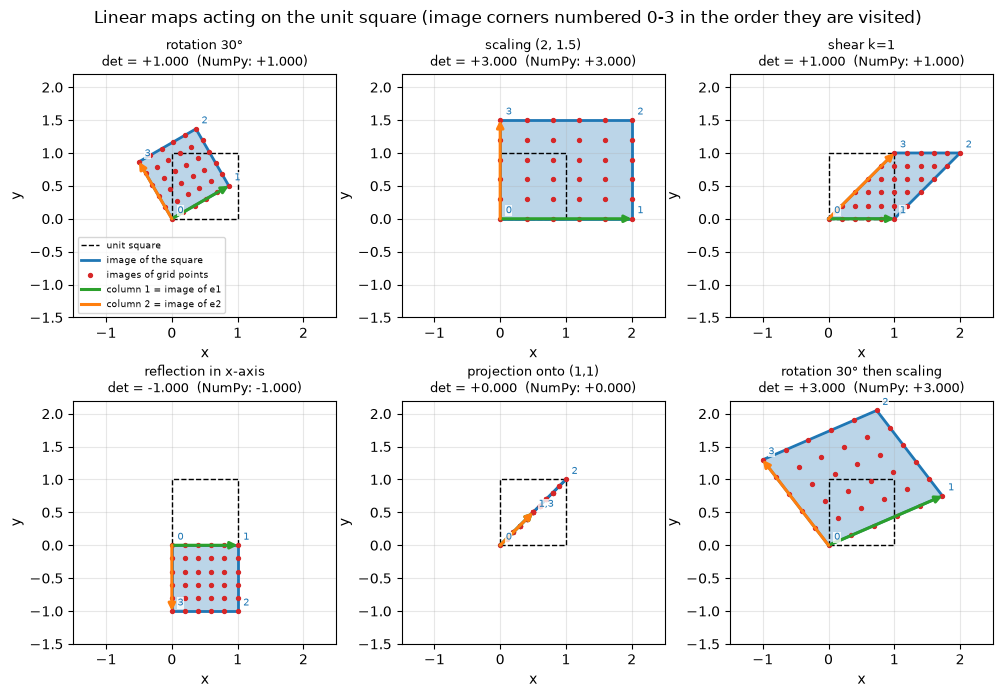

det(S @ R) = 3.0000   det(S) * det(R) = 3.0000   (= 3.0 x 1.0)


In [4]:
def rotation(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

def scaling(sx, sy):
    return np.array([[sx, 0.], [0., sy]])

def shear(k):
    return np.array([[1., k], [0., 1.]])

def reflection_x():
    return np.array([[1., 0.], [0., -1.]])

def projection(u):
    u = np.asarray(u, dtype=float); u = u / np.linalg.norm(u)
    return np.outer(u, u)

def det2(M):
    return M[0, 0] * M[1, 1] - M[0, 1] * M[1, 0]

square = np.array([[0, 1, 1, 0, 0],      # x coordinates of the corners (closed polygon)
                   [0, 0, 1, 1, 0.]])    # y coordinates
grid = np.array([[gx, gy] for gx in np.linspace(0, 1, 6) for gy in np.linspace(0, 1, 6)]).T

maps = {"rotation 30°": rotation(np.pi / 6), "scaling (2, 1.5)": scaling(2, 1.5),
        "shear k=1": shear(1.0), "reflection in x-axis": reflection_x(),
        "projection onto (1,1)": projection([1, 1]), "rotation 30° then scaling": scaling(2, 1.5) @ rotation(np.pi / 6)}

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (name, M) in zip(axes.ravel(), maps.items()):
    img, g_img = M @ square, M @ grid
    ax.plot(square[0], square[1], "k--", lw=1, label="unit square")
    ax.fill(img[0], img[1], alpha=0.3, color="tab:blue")
    ax.plot(img[0], img[1], color="tab:blue", lw=2, label="image of the square")
    ax.scatter(g_img[0], g_img[1], s=8, color="tab:red", label="images of grid points", zorder=3)
    for k, (col, lab) in enumerate([("tab:green", "column 1 = image of e1"), ("tab:orange", "column 2 = image of e2")]):
        ax.annotate("", xy=M[:, k], xytext=(0, 0), zorder=5,
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=2.2, shrinkA=0, shrinkB=0))
        ax.plot([], [], color=col, lw=2.2, label=lab)               # an empty line gives the arrow its legend entry
    names_at = {}                                                    # number the image corners 0 -> 1 -> 2 -> 3 (merge coinciding ones)
    for k, corner in enumerate(img[:, :4].T):
        names_at.setdefault(tuple(np.round(corner, 6)), []).append(str(k))
    for corner, ks in names_at.items():
        ax.annotate(",".join(ks), corner, textcoords="offset points", xytext=(4, 4), fontsize=7, color="tab:blue", zorder=6,
                    bbox=dict(fc="white", ec="none", alpha=0.8, pad=0.5))      # white backing so the numbers stay legible over dots and outlines
    ax.set_title(f"{name}\ndet = {det2(M):+.3f}  (NumPy: {np.linalg.det(M):+.3f})", fontsize=9)
    ax.set_xlim(-1.5, 2.5); ax.set_ylim(-1.5, 2.2); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=6.5, loc="lower left")
plt.suptitle("Linear maps acting on the unit square (image corners numbered 0-3 in the order they are visited)")
plt.tight_layout(); plt.show()

S_, R_ = scaling(2, 1.5), rotation(np.pi / 6)
print(f"det(S @ R) = {det2(S_ @ R_):.4f}   det(S) * det(R) = {det2(S_) * det2(R_):.4f}   (= 3.0 x 1.0)")

**Notice that** the rotation and the shear both have determinant $+1$ — the slanted parallelogram has
exactly the same area as the square — while the scaling by $(2, 1.5)$ has determinant $+3$: its image
is a $2 \times 1.5$ rectangle, three times the area. The reflection has determinant $-1$: same area,
but the corners numbered 0, 1, 2, 3 now run clockwise instead of counter-clockwise, because the second
column lies clockwise of the first. The projection has determinant $0$: its corners 1 and 3 land on
the same point, and the red grid points, which were spread over the square, now all lie on one line.
Pairs of different inputs have become the same output, and no matrix can undo that. Composition
multiplies determinants: the last panel (rotate by $30^\circ$, then scale) has determinant
$1 \times 3 = 3$, as the printed line confirms.

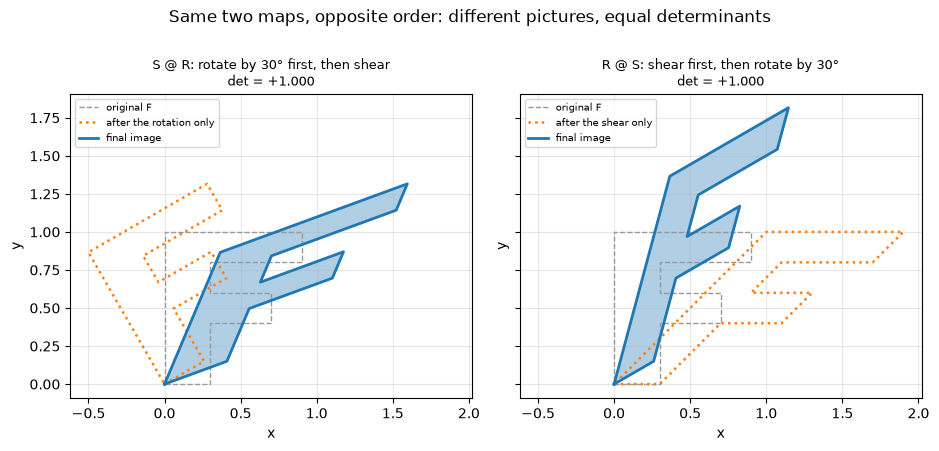

S @ R =
 [[1.366 0.366]
 [0.5   0.866]] 
R @ S =
 [[0.866 0.366]
 [0.5   1.366]] 
equal: False


In [5]:
# The order of two maps matters: the same rotation and shear applied to an asymmetric letter F, in both orders
F_shape = np.array([[0, .3, .3, .7, .7, .3, .3, .9, .9, 0, 0],
                    [0, 0, .4, .4, .6, .6, .8, .8, 1, 1, 0]])       # a closed polygon without any symmetry
R30, S1 = rotation(np.pi / 6), shear(1.0)                             # helpers from the cell above
orders_ = [("S @ R: rotate by 30° first, then shear", S1 @ R30, R30, "after the rotation only"),
           ("R @ S: shear first, then rotate by 30°", R30 @ S1, S1, "after the shear only")]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6), sharex=True, sharey=True)
for ax, (title, M_, first_, lab_) in zip(axes, orders_):
    ax.plot(*F_shape, color="0.6", ls="--", lw=1, label="original F")
    ax.plot(*(first_ @ F_shape), color="tab:orange", ls=":", lw=1.8, label=lab_)
    ax.fill(*(M_ @ F_shape), color="tab:blue", alpha=0.35)
    ax.plot(*(M_ @ F_shape), color="tab:blue", lw=2, label="final image")
    ax.set_title(f"{title}\ndet = {det2(M_):+.3f}", fontsize=9)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="upper left")
plt.suptitle("Same two maps, opposite order: different pictures, equal determinants")
plt.tight_layout(); plt.show()
print("S @ R =\n", S1 @ R30, "\nR @ S =\n", R30 @ S1, "\nequal:", np.allclose(S1 @ R30, R30 @ S1))

**Notice that** the same two maps give two different pictures when they are applied in the opposite
order: `S @ R` rotates first and shears second (a product acts on its right factor first), `R @ S`
does it the other way round, and the printed products differ in their diagonal entries. Yet both have
determinant $+1$ — determinants are plain numbers and commute, matrices do not. The orange dotted
letter is the intermediate step, so read each panel from the dashed original, through the orange
letter, to the blue one: exactly the right-to-left order in which you read the product.

## 4. Special matrices and what they promise

* **Orthogonal** $Q$: $Q^\top Q = I$, so $Q^{-1} = Q^\top$ and $\lVert Q\mathbf{x}\rVert = \lVert\mathbf{x}\rVert$ — lengths and angles survive.
* **Symmetric PSD**: $A = A^\top$ and $\mathbf{x}^\top A\mathbf{x} \ge 0$; every $A^\top A$ is one, because $\mathbf{x}^\top A^\top A\mathbf{x} = \lVert A\mathbf{x}\rVert^2$.
* **Triangular**: solve by back-substitution in $O(n^2)$ instead of $O(n^3)$.
* **Transpose rule**: $(AB)^\top = B^\top A^\top$ — the order flips.

In [6]:
Q = rotation(np.pi / 4)                                   # rotations are orthogonal
v = rng.standard_normal(2)
print("Q^T Q =\n", Q.T @ Q)
print("||v|| = %.4f   ||Qv|| = %.4f" % (np.linalg.norm(v), np.linalg.norm(Q @ v)))

M = rng.standard_normal((5, 3))
G = M.T @ M                                               # Gram matrix: symmetric and PSD
print("\nG symmetric:", np.allclose(G, G.T), "   eigenvalues of G:", np.linalg.eigvalsh(G))
for _ in range(3):
    z = rng.standard_normal(3)
    print("  z^T G z = %.3f  (= ||Mz||^2 = %.3f)" % (z @ G @ z, np.sum((M @ z) ** 2)))

K = np.array([[1., 2.], [2., 1.]])                        # symmetric but NOT PSD
z = np.array([1., -1.])
print("\nz^T K z for K=[[1,2],[2,1]], z=(1,-1):", z @ K @ z, "  eigenvalues:", np.linalg.eigvalsh(K))

A, B = rng.standard_normal((3, 2)), rng.standard_normal((2, 4))
print("\n(AB)^T == B^T A^T :", np.allclose((A @ B).T, B.T @ A.T))

# back-substitution on an upper-triangular system
U = np.array([[2., 1., -1.], [0., 3., 2.], [0., 0., 4.]])
b = np.array([3., 11., 8.])
x = np.zeros(3)
for i in range(2, -1, -1):
    x[i] = (b[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
print("back-substitution x =", x, "  check U @ x =", U @ x)

Q^T Q =
 [[1. 0.]
 [0. 1.]]
||v|| = 1.3088   ||Qv|| = 1.3088

G symmetric: True    eigenvalues of G: [ 1.7609  3.6848 17.5874]
  z^T G z = 6.155  (= ||Mz||^2 = 6.155)
  z^T G z = 17.999  (= ||Mz||^2 = 17.999)
  z^T G z = 2.589  (= ||Mz||^2 = 2.589)

z^T K z for K=[[1,2],[2,1]], z=(1,-1): -2.0   eigenvalues: [-1.  3.]

(AB)^T == B^T A^T : True
back-substitution x = [1.3333 2.3333 2.    ]   check U @ x = [ 3. 11.  8.]


**Notice that** $\mathbf{z}^\top G\mathbf{z}$ equals $\lVert M\mathbf{z}\rVert^2$ for every draw — that is the whole
proof that Gram matrices are positive semidefinite, and it is why covariance matrices (which are
Gram matrices of centred data) always have non-negative eigenvalues. The matrix `K` looks harmless
but gives a negative quadratic form, so it cannot be a covariance matrix. The back-substitution
loop solved a $3\times3$ system with only $3 + 2 + 1 = 6$ multiplications and divisions in all
($n(n+1)/2$ for an $n\times n$ system): the triangular structure is what `np.linalg.solve` buys
itself by first factoring $A = LU$.

**Try it yourself:** replace `rotation(np.pi/4)` with `shear(1.0)` and re-run. Is $Q^\top Q$ still the
identity? Which norms change?

## 5. Rank, column space and null space — collinear features

$\operatorname{rank} A$ is the number of independent columns; $\dim\mathcal{N}(A) = n - \operatorname{rank} A$
(rank–nullity). In a data matrix a rank deficiency means some feature is an exact linear
combination of others, so the regression coefficients are not identifiable. Below, a synthetic
feature matrix with 1,000 rows contains an exact duplicate (a unit conversion) and a one-hot
group that sums to the intercept — the *dummy-variable trap*.

In [7]:
n = 1000
age = rng.uniform(20, 80, n)
weight_kg = rng.normal(75, 12, n)
height_cm = rng.normal(172, 9, n)
weight_lb = 2.2046 * weight_kg                                   # exact duplicate information
device = rng.integers(0, 3, n)                                   # 0 = mobile, 1 = desktop, 2 = tablet
one_hot = np.eye(3)[device]                                      # three 0/1 columns
intercept = np.ones(n)

X_good = np.column_stack([intercept, age, weight_kg, height_cm, one_hot[:, 1:]])   # drop one level
X_bad = np.column_stack([intercept, age, weight_kg, height_cm, weight_lb, one_hot])  # both traps

for name, X in [("X_good", X_good), ("X_bad", X_bad)]:
    r = np.linalg.matrix_rank(X)
    print(f"{name}: shape {X.shape}, rank {r}, null-space dimension {X.shape[1] - r}")

# null space of X_bad from the SVD: right-singular vectors with (numerically) zero singular value
_, s, Vt = np.linalg.svd(X_bad, full_matrices=False)
print("\nsingular values of X_bad:", s[:6], "  smallest two: %.1e and %.1e (rounding noise, i.e. zero)" % tuple(s[6:]))
null_basis = Vt[s < 1e-8 * s.max()]

def tidy_basis(N, tol=1e-9):
    # row-reduce a basis of the null space so that each vector spells out ONE dependency
    N = N.copy(); r = 0
    for c in range(N.shape[1]):
        if r == N.shape[0]:
            break
        piv = r + np.argmax(np.abs(N[r:, c]))
        if abs(N[piv, c]) < tol:
            continue
        N[[r, piv]] = N[[piv, r]]; N[r] /= N[r, c]
        for i in range(N.shape[0]):
            if i != r:
                N[i] -= N[i, c] * N[r]
        r += 1
    N[np.abs(N) < 1e-6] = 0.0
    return N

cols = ["intercept", "age", "weight_kg", "height_cm", "weight_lb", "mobile", "desktop", "tablet"]
for z in tidy_basis(null_basis):
    relation = " ".join(f"{v:+.4f}*{c}" for c, v in zip(cols, z) if v != 0)
    print("null vector:", relation, "= 0   -> ||X_bad z|| = %.1e" % np.linalg.norm(X_bad @ z))

X_good: shape (1000, 6), rank 6, null-space dimension 0
X_bad: shape (1000, 8), rank 6, null-space dimension 2

singular values of X_bad: [8086.0142  681.7715  541.7147   18.615    17.8286    1.7862]   smallest two: 4.3e-13 and 2.8e-15 (rounding noise, i.e. zero)
null vector: +1.0000*intercept -1.0000*mobile -1.0000*desktop -1.0000*tablet = 0   -> ||X_bad z|| = 6.3e-15
null vector: +1.0000*weight_kg -0.4536*weight_lb = 0   -> ||X_bad z|| = 5.5e-13


**Notice that** `X_bad` has 8 columns but rank 6: the null space is two-dimensional, and the two
null vectors spell out exactly which columns are redundant — one says
`weight_kg - 0.4536 * weight_lb = 0` (i.e. $1/2.2046 = 0.4536$), the other says
`intercept - mobile - desktop - tablet = 0`. Any linear combination of these two vectors can be
added to a coefficient vector without changing a single prediction, so the "effect of weight" or
"effect of being on mobile" is meaningless until one column from each group is dropped (or a ridge
penalty is added). `X_good` does that and has full column rank.

exact duplicate  : lstsq answer [3.1 3.1], sum of the two coefficients 6.19
sloppy duplicate : lstsq answer [5.89 0.31], sum of the two coefficients 6.20


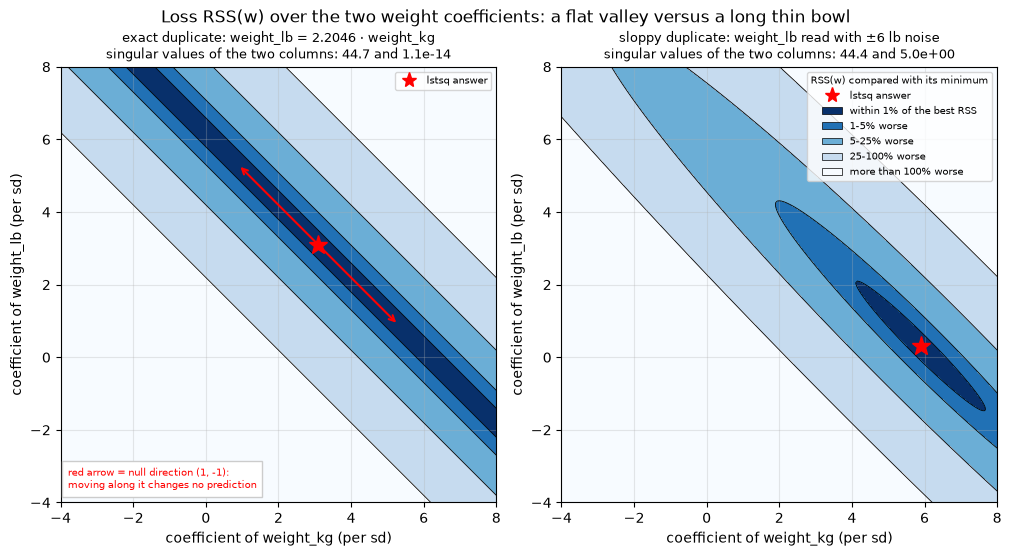

In [8]:
# What a null-space direction does to the loss: a flat valley (exact duplicate) vs a long thin bowl (sloppy duplicate)
from matplotlib.patches import Patch
g_ = np.random.default_rng(11)                                # its own generator: the lesson's rng stream stays untouched
y_dem = 0.5 * weight_kg + g_.normal(0, 4.0, len(weight_kg))   # an outcome that depends on weight
yc_ = y_dem - y_dem.mean()
lb_sloppy = weight_lb + g_.normal(0, 6.0, len(weight_kg))     # the same weight read off a second, sloppy scale (±6 lb)
zs = lambda v: (v - v.mean()) / v.std()                       # per-standard-deviation units, so both axes are comparable
cases_ = [("exact duplicate: weight_lb = 2.2046 · weight_kg", np.column_stack([zs(weight_kg), zs(weight_lb)])),
          ("sloppy duplicate: weight_lb read with ±6 lb noise", np.column_stack([zs(weight_kg), zs(lb_sloppy)]))]
gw_ = np.linspace(-4, 8, 241); W1_, W2_ = np.meshgrid(gw_, gw_)
band_levels = [1, 1.01, 1.05, 1.25, 2, 1e9]                   # bands of RSS(w) / RSS_min
band_cols = ["#08306b", "#2171b5", "#6baed6", "#c6dbef", "#f7fbff"]
fig, axes = plt.subplots(1, 2, figsize=(10, 5.4), layout="constrained")
for ax, (title, Z_) in zip(axes, cases_):
    w_min = np.linalg.lstsq(Z_, yc_, rcond=None)[0]           # the minimum-norm minimiser (what lstsq returns)
    G_ = Z_.T @ Z_; rss_min = np.sum((yc_ - Z_ @ w_min) ** 2)
    D1, D2 = W1_ - w_min[0], W2_ - w_min[1]
    rel = 1 + (G_[0, 0] * D1 ** 2 + 2 * G_[0, 1] * D1 * D2 + G_[1, 1] * D2 ** 2) / rss_min     # RSS(w) / RSS_min
    ax.contourf(W1_, W2_, rel, levels=band_levels, colors=band_cols)
    ax.contour(W1_, W2_, rel, levels=band_levels[1:-1], colors="k", linewidths=0.6)
    ax.plot(*w_min, "r*", ms=14)
    s_ = np.linalg.svd(Z_, compute_uv=False)
    ax.set_title(f"{title}\nsingular values of the two columns: {s_[0]:.1f} and {s_[1]:.1e}", fontsize=9)
    ax.set_xlabel("coefficient of weight_kg (per sd)"); ax.set_ylabel("coefficient of weight_lb (per sd)")
    ax.set_xlim(-4, 8); ax.set_ylim(-4, 8); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    print(f"{title.split(':')[0]:17s}: lstsq answer {np.round(w_min, 2)}, sum of the two coefficients {w_min.sum():.2f}")
    if title.startswith("exact"):
        ax.annotate("", xy=w_min + [2.2, -2.2], xytext=w_min - [2.2, -2.2], arrowprops=dict(arrowstyle="<->", color="red", lw=1.5))
        ax.text(-3.8, -3.6, "red arrow = null direction (1, -1):\nmoving along it changes no prediction", color="red", fontsize=7,
                bbox=dict(fc="white", ec="0.8"))
band_names = ["within 1% of the best RSS", "1-5% worse", "5-25% worse", "25-100% worse", "more than 100% worse"]
star_ = plt.Line2D([], [], color="r", marker="*", ls="", ms=11, label="lstsq answer")
axes[0].legend(handles=[star_], fontsize=7, loc="upper right")
axes[1].legend(handles=[star_] + [Patch(facecolor=c, edgecolor="k", linewidth=0.5, label=nm) for c, nm in zip(band_cols, band_names)],
               fontsize=7, loc="upper right", title="RSS(w) compared with its minimum", title_fontsize=7)
plt.suptitle("Loss RSS(w) over the two weight coefficients: a flat valley versus a long thin bowl")
plt.show()

**Notice that** with an exact duplicate the loss has a flat-bottomed valley: every pair of
coefficients with the same sum fits equally well, so no amount of data can say how the effect of
weight is split between the two columns, and `lstsq` merely picks the pair of smallest norm. The red
arrow is the null vector found above — $(1, -0.4536)$ in raw units, $(1, -1)$ per standard deviation —
and the second singular value in the title, zero up to rounding noise, is that flat direction. A sloppy
duplicate closes the valley into a long thin ellipse: there is now a unique minimum, but it is pinned
down only *across* the valley, not *along* it — the situation Section 6 measures with the condition
number.

## 6. Solving $A\mathbf{x} = \mathbf{b}$: `solve`, not `inv`

For an invertible square $A$ the solution is $\mathbf{x} = A^{-1}\mathbf{b}$ *on paper*. In code,
`np.linalg.solve` factors $A = LU$ and does two triangular solves — about $\tfrac23 n^3$ flops versus
roughly $2n^3$ for the explicit inverse — and returns an $\mathbf{x}$ that solves the system you wrote
down to rounding level, which `inv(A) @ b` does not guarantee. How many digits of the answer survive
is governed by the **condition number** $\kappa(A)$: relative perturbations of the data can be
amplified by up to $\kappa(A)$ in the solution.

We solve the juice-blending system from the guide, time `solve` against `inv`, push a $2\times2$
matrix towards singularity to watch the error grow with $\kappa$, draw *why* it grows (a round ball of
noise becomes a sliver), and finish with Hilbert matrices, where `inv(A) @ b` visibly fails and
`solve` does not.

blend (dl of each concentrate): [2. 3. 1.]   residual: 0.0
600x600: solve 2.4 ms   inv(A) @ b 8.4 ms   ratio 3.5x


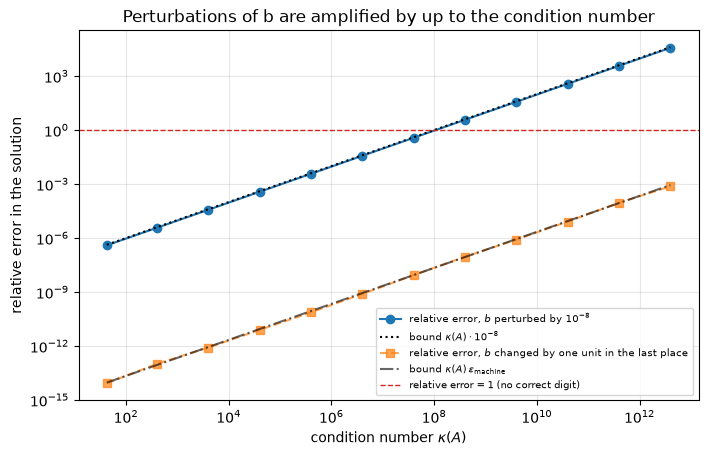

kappa * 1e-8 exceeds 1 (no correct digits left) once kappa > 1e8; here kappa reaches 4e+12
one-ulp error / (kappa * 2.2e-16) lies between 0.84 and 1.17 at all 12 points

eps = 1e-4: kappa = 4.0e+04
b = (2, 2.0001) -> x = [1. 1.]
b = (2, 2.0002) -> x = [0. 2.]
b changed by 1e-04 in its second entry: 5.0e-05 relative to that entry, 3.5e-05 relative to ||b|| -- yet x moved by 100%


In [9]:
A = np.array([[1., 1., 2.],
              [2., 1., 1.],
              [1., 3., 1.]])
b = np.array([7., 8., 12.])
x = np.linalg.solve(A, b)
print("blend (dl of each concentrate):", x, "  residual:", np.linalg.norm(A @ x - b))

# cost: solve vs inverse on a 600x600 system
M = rng.standard_normal((600, 600)); rhs = rng.standard_normal(600)
t0 = time.perf_counter(); [np.linalg.solve(M, rhs) for _ in range(5)]; t_solve = (time.perf_counter() - t0) / 5
t0 = time.perf_counter(); [np.linalg.inv(M) @ rhs for _ in range(5)]; t_inv = (time.perf_counter() - t0) / 5
print(f"600x600: solve {t_solve*1000:.1f} ms   inv(A) @ b {t_inv*1000:.1f} ms   ratio {t_inv / t_solve:.1f}x")

# sensitivity: a family of increasingly ill-conditioned 2x2 matrices.
# We perturb b by a *relative* 1e-8 (think: measurement noise in the 8th digit) and watch
# how far the solution moves; the condition number predicts the amplification.
x_true = np.array([0.3, 0.7])
delta = 1e-8
eps_values = 10.0 ** -np.arange(1, 13)
kappas, err_pert, err_ulp = [], [], []
for eps in eps_values:
    A2 = np.array([[1., 1.], [1., 1. + eps]])
    b2 = A2 @ x_true
    b_noisy = b2 * (1 + delta * np.array([1., -1.]))          # relative perturbation of size delta
    b_ulp = b2 + np.spacing(b2) * np.array([1., -1.])         # the smallest possible change: one unit in the last place
    kappas.append(np.linalg.cond(A2))
    err_pert.append(np.linalg.norm(np.linalg.solve(A2, b_noisy) - x_true) / np.linalg.norm(x_true))
    err_ulp.append(np.linalg.norm(np.linalg.solve(A2, b_ulp) - x_true) / np.linalg.norm(x_true))
kappas, err_ulp = np.array(kappas), np.array(err_ulp)

plt.figure(figsize=(8, 4.8))
plt.loglog(kappas, err_pert, "o-", label=r"relative error, $b$ perturbed by $10^{-8}$")
plt.loglog(kappas, kappas * delta, "k:", label=r"bound $\kappa(A)\cdot 10^{-8}$")
plt.loglog(kappas, err_ulp, "s--", alpha=0.7, label=r"relative error, $b$ changed by one unit in the last place")
plt.loglog(kappas, kappas * 2.2e-16, "k-.", alpha=0.6, label=r"bound $\kappa(A)\,\varepsilon_{\mathrm{machine}}$")
plt.axhline(1, color="tab:red", ls="--", lw=1, label="relative error = 1 (no correct digit)")
plt.xlabel(r"condition number $\kappa(A)$"); plt.ylabel("relative error in the solution")
plt.title("Perturbations of b are amplified by up to the condition number")
plt.legend(fontsize=7.5, loc="lower right"); plt.grid(alpha=0.3, which="both"); plt.show()
print("kappa * 1e-8 exceeds 1 (no correct digits left) once kappa > 1e8; here kappa reaches %.0e" % kappas[-1])
print("one-ulp error / (kappa * 2.2e-16) lies between %.2f and %.2f at all %d points" % ((err_ulp / (kappas * 2.2e-16)).min(), (err_ulp / (kappas * 2.2e-16)).max(), len(kappas)))

print("\neps = 1e-4: kappa = %.1e" % kappas[3])
A4 = np.array([[1., 1.], [1., 1.0001]])
b_a, b_b = np.array([2., 2.0001]), np.array([2., 2.0002])
x_a, x_b = np.linalg.solve(A4, b_a), np.linalg.solve(A4, b_b)
print("b = (2, 2.0001) -> x =", x_a)
print("b = (2, 2.0002) -> x =", x_b)
db = b_b - b_a
print("b changed by %.0e in its second entry: %.1e relative to that entry, %.1e relative to ||b|| -- yet x moved by %.0f%%"
      % (db[1], db[1] / b_a[1], np.linalg.norm(db) / np.linalg.norm(b_a), 100 * np.linalg.norm(x_b - x_a) / np.linalg.norm(x_a)))

**Notice that** the circles hug the dotted line $\kappa(A)\cdot 10^{-8}$: a perturbation in the eighth
digit of $\mathbf{b}$ is amplified by almost exactly the condition number, and once
$\kappa > 10^{8}$ the relative error in $\mathbf{x}$ exceeds 1 (the red line) — not a single digit of
the answer is reliable. The squares show the smallest change of $\mathbf{b}$ a computer can even
represent, one unit in the last place (a relative change of about $10^{-16}$): they sit on the
dash-dotted line $\kappa(A)\,\varepsilon_{\text{machine}}$ with $\varepsilon_{\text{machine}} \approx 2\times10^{-16}$ —
the same slope, eight orders lower. With $\kappa = 10^{10}$ you keep about six digits, with $10^{16}$ none.
Conditioning is a property of the *problem*, not of the algorithm; `inv` cannot fix it and typically
costs two to five times as much as `solve` (three by the flop count). The last lines are the guide's
example: a change in the last printed digit of $\mathbf{b}$ (the fourth decimal) moves the solution
from $(1, 1)$ to $(0, 2)$, because the two columns of $A$ are almost parallel.

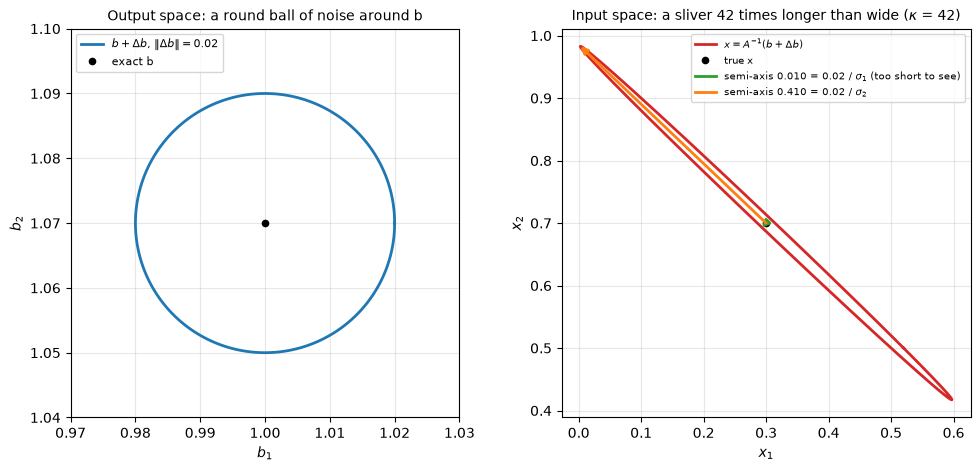

sigma_1 = 2.051, sigma_2 = 0.0488, kappa = sigma_1 / sigma_2 = 42.1;  long axis of the sliver along v_2 = [-0.72  0.69]
noise radius 0.02 is 1.4% of ||b||, yet x_1 can be anywhere in [0.00, 0.60] although the true value is 0.3


In [10]:
# kappa as an aspect ratio: a round ball of noise in b becomes a long sliver of candidate solutions x
A_c = np.array([[1., 1.], [1., 1.1]])                        # the eps = 0.1 member of the family above
x_c = np.array([0.3, 0.7]); b_c = A_c @ x_c
U_c, s_c, Vt_c = np.linalg.svd(A_c)
radius = 0.02                                                # size of the measurement noise in b
phi = np.linspace(0, 2 * np.pi, 361)
ball = radius * np.vstack([np.cos(phi), np.sin(phi)])        # every perturbation of 2-norm 0.02
cloud = np.linalg.solve(A_c, b_c[:, None] + ball)            # the solutions that these noisy right-hand sides lead to
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.6), layout="constrained")
ax1.plot(*(b_c[:, None] + ball), color="tab:blue", lw=2, label=r"$b+\Delta b$, $\|\Delta b\| = 0.02$")
ax1.plot(*b_c, "k.", ms=9, label="exact b")
ax1.set_xlabel("$b_1$"); ax1.set_ylabel("$b_2$"); ax1.set_title("Output space: a round ball of noise around b", fontsize=10)
ax1.set_aspect("equal"); ax1.margins(0.25); ax1.legend(fontsize=8, loc="upper left"); ax1.grid(alpha=0.3)
ax2.plot(*cloud, color="tab:red", lw=2, label=r"$x = A^{-1}(b + \Delta b)$")
ax2.plot(*x_c, "k.", ms=9, label="true x")
for k_, col_ in enumerate(["tab:green", "tab:orange"]):
    ax2.annotate("", xy=x_c + Vt_c[k_] * radius / s_c[k_], xytext=x_c, arrowprops=dict(arrowstyle="-|>", color=col_, lw=2, shrinkA=0, shrinkB=0))
    ax2.plot([], [], color=col_, lw=2, label=r"semi-axis %.3f = 0.02 / $\sigma_%d$" % (radius / s_c[k_], k_ + 1)
             + (" (too short to see)" if k_ == 0 else ""))
ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$")
ax2.set_title(rf"Input space: a sliver {s_c[0] / s_c[1]:.0f} times longer than wide ($\kappa$ = {np.linalg.cond(A_c):.0f})", fontsize=10)
ax2.set_aspect("equal"); ax2.legend(fontsize=7.5, loc="upper right"); ax2.grid(alpha=0.3)
plt.show()
print("sigma_1 = %.3f, sigma_2 = %.4f, kappa = sigma_1 / sigma_2 = %.1f;  long axis of the sliver along v_2 = %s" % (s_c[0], s_c[1], s_c[0] / s_c[1], np.round(Vt_c[1], 2)))
print("noise radius %.2f is %.1f%% of ||b||, yet x_1 can be anywhere in [%.2f, %.2f] although the true value is %.1f"
      % (radius, 100 * radius / np.linalg.norm(b_c), cloud[0].min(), cloud[0].max(), x_c[0]))

**Notice that** a perfectly round ball of measurement noise in $\mathbf{b}$ becomes a sliver $42$ times
longer than wide in $\mathbf{x}$: its semi-axes are the noise radius divided by the singular values
$\sigma_1 = 2.05$ and $\sigma_2 = 0.049$, so their ratio is $\sigma_1/\sigma_2 = \kappa(A)$. The first
coordinate $x_1$ can therefore be anywhere between $0$ and $0.6$ although its true value is $0.3$ —
an uncertainty of about $100\%$ from noise of $1.4\%$ — and the long direction, $\mathbf{v}_2$ (up to sign
$(-0.72, 0.69)$), is where the two almost equal columns of $A$ trade off against each other. This is
the circle-to-ellipse picture of Section 8 with $A^{-1}$ in place of $A$: the axis ratio of the ellipse is
a ratio of singular values, which the SVD of Module 03 makes precise. At $\kappa = 4\times10^{12}$ the
sliver would be four trillion times longer than wide.

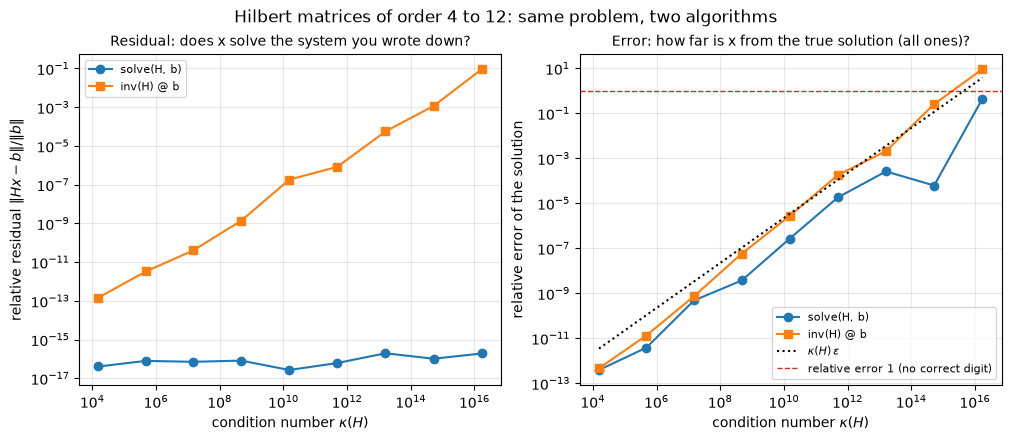

order 10: kappa = 1.6e+13, relative residual: solve 2e-16, inv(H) @ b 6e-05


In [11]:
# Same problem, two algorithms: solve returns an x that solves the system you wrote down, inv(A) @ b does not (Hilbert matrices)
orders_h = np.arange(4, 13)
kap_h, res_s, res_i, err_s, err_i = [], [], [], [], []
for m_ in orders_h:
    H_h = 1.0 / (np.arange(m_)[:, None] + np.arange(m_)[None, :] + 1.0)      # Hilbert matrix 1/(i+j+1): kappa grows like e^(3.5 m)
    b_h = H_h @ np.ones(m_)                                                   # chosen so that the exact solution is all ones
    xs_, xi_ = np.linalg.solve(H_h, b_h), np.linalg.inv(H_h) @ b_h
    kap_h.append(np.linalg.cond(H_h))
    res_s.append(np.linalg.norm(H_h @ xs_ - b_h) / np.linalg.norm(b_h)); res_i.append(np.linalg.norm(H_h @ xi_ - b_h) / np.linalg.norm(b_h))
    err_s.append(np.linalg.norm(xs_ - 1) / np.sqrt(m_)); err_i.append(np.linalg.norm(xi_ - 1) / np.sqrt(m_))
kap_h = np.array(kap_h)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.3), layout="constrained")
ax1.loglog(kap_h, np.maximum(res_s, 1e-17), "o-", label="solve(H, b)")
ax1.loglog(kap_h, np.maximum(res_i, 1e-17), "s-", label="inv(H) @ b")
ax1.set_xlabel(r"condition number $\kappa(H)$"); ax1.set_ylabel(r"relative residual $\|Hx - b\| / \|b\|$")
ax1.set_title("Residual: does x solve the system you wrote down?", fontsize=10)
ax2.loglog(kap_h, err_s, "o-", label="solve(H, b)")
ax2.loglog(kap_h, err_i, "s-", label="inv(H) @ b")
ax2.loglog(kap_h, kap_h * np.finfo(float).eps, "k:", label=r"$\kappa(H)\,\varepsilon$")
ax2.axhline(1, color="tab:red", ls="--", lw=1, label="relative error 1 (no correct digit)")
ax2.set_xlabel(r"condition number $\kappa(H)$"); ax2.set_ylabel("relative error of the solution")
ax2.set_title("Error: how far is x from the true solution (all ones)?", fontsize=10)
for ax in (ax1, ax2):
    ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.suptitle("Hilbert matrices of order 4 to 12: same problem, two algorithms")
plt.show()
i10 = list(orders_h).index(10)
print("order 10: kappa = %.1e, relative residual: solve %.0e, inv(H) @ b %.0e" % (kap_h[i10], res_s[i10], res_i[i10]))

**Notice that** the residual of `solve` stays at rounding level (about $10^{-16}$) however
ill-conditioned the Hilbert matrix becomes, while `inv(H) @ b` misses the target by about $6\times10^{-5}$
at order 10 and by roughly $9\%$ at order 12 (the exact values depend on the LAPACK build, the pattern
does not). Neither error rises much above $\kappa\,\varepsilon$ (the dotted line): `inv(H) @ b` hovers
around it, `solve` sits well below it. Conditioning is a property of the *problem*: the rounding already
present in the stored entries of $H$ is amplified by $\kappa$ whatever algorithm follows. But only
`solve` hands back an $\mathbf{x}$ that solves the system you actually wrote down: its answer is the
exact solution of a system whose matrix differs from $H$ only in the last digits (*backward
stability*), and `inv(H) @ b` offers no such guarantee.

**Try it yourself:** change `delta` in the sensitivity cell to `1e-4` (noise in the fourth digit) and read
off the largest $\kappa$ for which the solution still has two correct digits. Then, back with the
matrix `X_bad` of Section 5, solve `X_bad.T @ X_bad` against `X_bad.T @ y` for
`y = 50 + 10 * np.random.default_rng(0).standard_normal(1000)` (its own generator, so the lesson's `rng`
stays untouched), once as it is and once with the right-hand side multiplied by `(1 + 1e-10)`. You will
probably see no error at all — the Gram matrix is singular only up to rounding (its condition number is
of order $10^{17}$ or more), which LAPACK does not necessarily notice, so do not count on an exception —
yet the intercept moves by several units (about $-8.3$ in the reference run; the exact amount depends on
rounding and on the LAPACK build) while each of the three dummy coefficients moves by the same amount in
the opposite direction, `weight_kg` and `weight_lb` move in the ratio $1 : -0.4536$, and the predictions
`X_bad @ w` change by only about $10^{-10}$ in relative terms: the two null vectors above at work.

## 7. Least squares three ways

With more observations than parameters, $A\mathbf{x} = \mathbf{y}$ has no exact solution. The
least-squares solution minimises $\lVert A\mathbf{x} - \mathbf{y}\rVert^2$; the residual must be orthogonal to
every column, $A^\top(\mathbf{y} - A\hat{\mathbf{x}}) = \mathbf{0}$, giving the **normal equations**

$$
A^\top A\,\hat{\mathbf{x}} = A^\top\mathbf{y}, \qquad \hat{\mathbf{y}} = H\mathbf{y}, \quad H = A(A^\top A)^{-1}A^\top .
$$

We fit a line to noisy data by (a) the normal equations from scratch, (b) a QR factorisation
$A = QR$, so $R\hat{\mathbf{x}} = Q^\top\mathbf{y}$, and (c) `np.linalg.lstsq`, then check that the hat
matrix is a symmetric projection.

normal eq : [2.7489 0.41  ] 
QR        : [2.7489 0.41  ] 
lstsq     : [2.7489 0.41  ]
rank of A : 2    kappa(A) = 11.6   kappa(A^T A) = 134.8

H symmetric: True   H @ H == H: True   trace(H) = 2.0
residual orthogonal to the columns: A^T r = [0. 0.]
leverages (diag of H) range: 0.033 .. 0.127, mean 0.067 = p/n


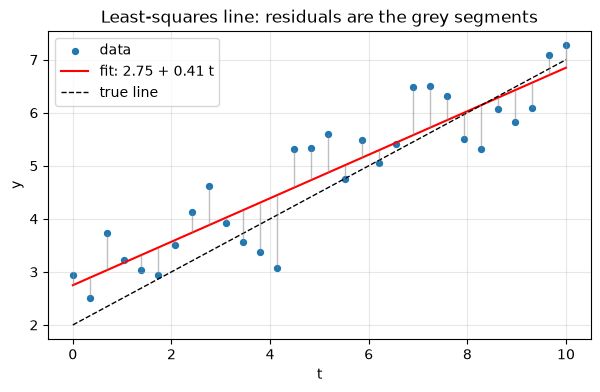

In [12]:
t = np.linspace(0, 10, 30)
y = 2.0 + 0.5 * t + rng.normal(0, 0.8, t.size)          # true line: intercept 2, slope 0.5
A = np.column_stack([np.ones_like(t), t])              # design matrix (30 x 2)

# (a) normal equations, solved (not inverted)
x_normal = np.linalg.solve(A.T @ A, A.T @ y)
# (b) QR: A = Q R  ->  R x = Q^T y  (triangular, well conditioned)
Qm, Rm = np.linalg.qr(A)
x_qr = np.linalg.solve(Rm, Qm.T @ y)
# (c) library call (SVD-based)
x_lstsq, residual_ss, rank, sv = np.linalg.lstsq(A, y, rcond=None)
print("normal eq :", x_normal, "\nQR        :", x_qr, "\nlstsq     :", x_lstsq)
print("rank of A :", rank, "   kappa(A) = %.1f   kappa(A^T A) = %.1f" % (np.linalg.cond(A), np.linalg.cond(A.T @ A)))

# the hat matrix is a symmetric, idempotent projector with trace = number of parameters
H = A @ np.linalg.solve(A.T @ A, A.T)
r = y - H @ y
print("\nH symmetric:", np.allclose(H, H.T), "  H @ H == H:", np.allclose(H @ H, H), "  trace(H) =", np.trace(H).round(6))
print("residual orthogonal to the columns: A^T r =", A.T @ r)
print("leverages (diag of H) range: %.3f .. %.3f, mean %.3f = p/n" % (np.diag(H).min(), np.diag(H).max(), np.diag(H).mean()))

plt.scatter(t, y, s=18, label="data")
plt.plot(t, A @ x_lstsq, "r", label=f"fit: {x_lstsq[0]:.2f} + {x_lstsq[1]:.2f} t")
plt.plot(t, 2.0 + 0.5 * t, "k--", lw=1, label="true line")
plt.vlines(t, A @ x_lstsq, y, color="gray", alpha=0.5, lw=1)
plt.xlabel("t"); plt.ylabel("y"); plt.title("Least-squares line: residuals are the grey segments")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Notice that** all three routes give the same coefficients — they solve the same problem — but
$\kappa(A^\top A) = \kappa(A)^2$: forming the Gram matrix squares the condition number, which is
why `lstsq` and QR are preferred whenever $\kappa(A)$ is large (roughly $10^4$ or more), however many
columns there are. The hat matrix passes both projection tests, its trace is exactly 2 (the number of
parameters), and $A^\top\mathbf{r} = \mathbf{0}$ to rounding error: the residual vector really is
perpendicular to the column space. "Linear" least squares means linear *in the coefficients*: the same
machinery fits a quadratic once we add a $t^2$ column.

                      params     RSS  mean RSS, 2000 fresh draws  RMS gap to true curve    kappa(A)
line                       2   6.237                       7.592                  0.381     1.2e+01
quadratic                  3   2.209                       2.875                  0.077     1.4e+02
degree-6 polynomial        7   1.700                       3.392                  0.149     6.4e+06
on 89% of the 2000 fresh draws the degree-6 curve has a larger RSS than the quadratic


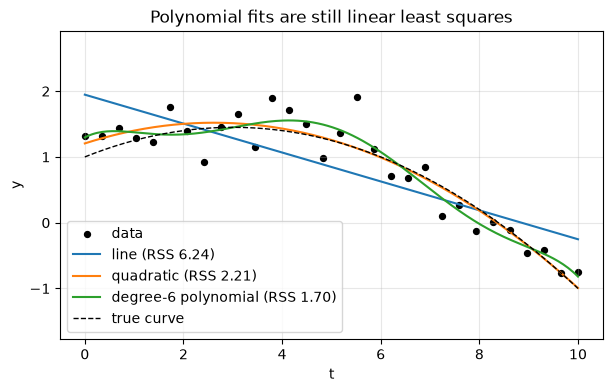

In [13]:
truth = lambda s: 1.0 + 0.3 * s - 0.05 * s ** 2                               # the curve behind the data
y2 = truth(t) + rng.normal(0, 0.3, t.size)                                    # curved truth plus noise
y_new = truth(t) + np.random.default_rng(99).normal(0, 0.3, (2000, t.size))   # 2000 fresh noise draws at the same t (own generator)
designs = {"line": np.column_stack([np.ones_like(t), t]),
           "quadratic": np.column_stack([np.ones_like(t), t, t ** 2]),
           "degree-6 polynomial": np.column_stack([t ** k for k in range(7)])}
tt = np.linspace(0, 10, 200)
print(f"{'':20s}  params     RSS  mean RSS, 2000 fresh draws  RMS gap to true curve    kappa(A)")
plt.scatter(t, y2, s=18, color="k", label="data")
fresh = {}                                                                    # per model: the RSS on each of the fresh draws
for name, A_d in designs.items():
    coef = np.linalg.lstsq(A_d, y2, rcond=None)[0]
    A_tt = np.column_stack([tt ** k for k in range(A_d.shape[1])])
    rss = np.sum((y2 - A_d @ coef) ** 2)
    fresh[name] = np.sum((y_new - A_d @ coef) ** 2, axis=1)              # the same fitted curve, judged on each fresh draw
    rss_new = fresh[name].mean()                                         # mean RSS of the fitted curve on the fresh draws
    gap = np.sqrt(np.mean((A_tt @ coef - truth(tt)) ** 2))               # RMS distance from the true curve on [0, 10]
    print(f"{name:20s}  {A_d.shape[1]:6d}  {rss:6.3f}  {rss_new:26.3f}  {gap:21.3f}  {np.linalg.cond(A_d):10.1e}")
    plt.plot(tt, A_tt @ coef, label=f"{name} (RSS {rss:.2f})")
print("on %.0f%% of the 2000 fresh draws the degree-6 curve has a larger RSS than the quadratic" % (100 * np.mean(fresh["degree-6 polynomial"] > fresh["quadratic"])))
plt.plot(tt, truth(tt), "k--", lw=1, label="true curve")
plt.ylim(y2.min() - 1, y2.max() + 1)
plt.xlabel("t"); plt.ylabel("y"); plt.title("Polynomial fits are still linear least squares")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Notice that** the residual sum of squares can only fall as columns are added — the column space
grows, so the projection gets closer — but the degree-6 fit buys very little over the quadratic
(RSS $2.21 \to 1.70$) while its design matrix has a condition number of about $6\times10^6$, some
$46{,}000$ times that of the quadratic ($140$). The dashed true curve shows what the extra columns
really bought: the degree-6 curve bends to chase the noise and is on average about twice as far from
the truth as the quadratic (RMS gap $0.15$ against $0.08$), and on fresh noise at the same $t$ values
(averaged over 2000 draws) it fits *worse* than the quadratic (RSS $3.392$ against $2.875$, as in the
table; worse on $89\%$ of the draws, as the last printed line says). More columns means a better fit to
*these* points, not a better model; Module 13 turns that tension into the bias–variance trade-off,
and Module 03's SVD explains the exploding condition number.

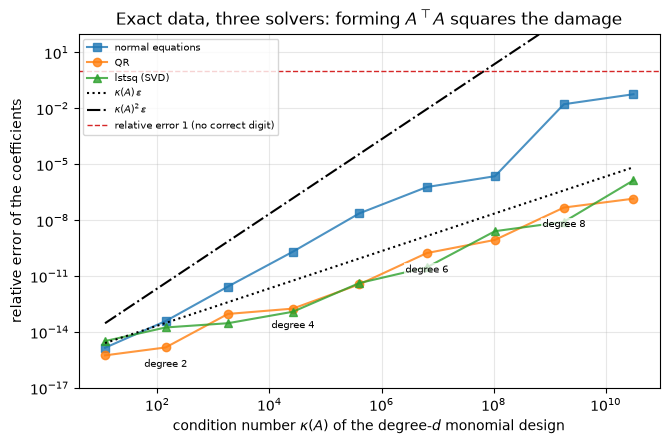

degree 6: kappa = 6.4e+06, correct digits  normal equations 6.2   QR 9.8   lstsq 10.5
degree 8: kappa = 1.8e+09, correct digits  normal equations 1.8   QR 7.3   lstsq 8.1


In [14]:
# The same exact problem, three solvers: forming A^T A makes the normal equations lose digits much faster than QR or lstsq
eps_mach = np.finfo(float).eps
kap_, err_ = [], {"normal equations": [], "QR": [], "lstsq (SVD)": []}
for deg in range(1, 10):
    A_p = np.column_stack([t ** k for k in range(deg + 1)])   # monomial design on the lesson's t in [0, 10]
    c_true = np.ones(deg + 1)
    y_p = A_p @ c_true                                        # noise-free data, so the exact least-squares answer is c_true
    Q_p, R_p = np.linalg.qr(A_p)
    sols = {"normal equations": np.linalg.solve(A_p.T @ A_p, A_p.T @ y_p),
            "QR": np.linalg.solve(R_p, Q_p.T @ y_p),
            "lstsq (SVD)": np.linalg.lstsq(A_p, y_p, rcond=None)[0]}
    kap_.append(np.linalg.cond(A_p))
    for k_, v_ in sols.items():
        err_[k_].append(np.linalg.norm(v_ - c_true) / np.linalg.norm(c_true))
kap_ = np.array(kap_)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for (k_, e_), mk in zip(err_.items(), ["s-", "o-", "^-"]):
    ax.loglog(kap_, e_, mk, alpha=0.8, label=k_)
ax.loglog(kap_, kap_ * eps_mach, "k:", label=r"$\kappa(A)\,\varepsilon$")
ax.loglog(kap_, kap_ ** 2 * eps_mach, "k-.", label=r"$\kappa(A)^2\,\varepsilon$")
ax.axhline(1, color="tab:red", ls="--", lw=1, label="relative error 1 (no correct digit)")
for deg in (2, 4, 6, 8):
    ax.annotate(f"degree {deg}", (kap_[deg - 1], err_["QR"][deg - 1]), textcoords="offset points", xytext=(0, -14), fontsize=7, ha="center",
                bbox=dict(fc="white", ec="none", alpha=0.75, pad=0.8))
ax.set_ylim(1e-17, 1e2)
ax.set_xlabel(r"condition number $\kappa(A)$ of the degree-$d$ monomial design"); ax.set_ylabel("relative error of the coefficients")
ax.set_title(r"Exact data, three solvers: forming $A^\top A$ squares the damage")
ax.legend(fontsize=7, loc="upper left"); ax.grid(alpha=0.3, which="both"); plt.show()
for deg in (6, 8):
    print("degree %d: kappa = %.1e, correct digits  normal equations %.1f   QR %.1f   lstsq %.1f"
          % (deg, kap_[deg - 1], *(-np.log10(err_[k_][deg - 1]) for k_ in err_)))

**Notice that** QR and `lstsq` stay close to the line $\kappa\,\varepsilon$ while the normal equations
lose digits much faster, between $\kappa\,\varepsilon$ and $\kappa^2\varepsilon$: on the degree-6
design of the previous cell ($\kappa = 6\times10^6$) they return about 6 correct digits against 10, and
at degree 8 ($\kappa = 2\times10^9$) only 2 against 7 or 8. The data and the exact answer are
identical — forming $A^\top A$ is what squares the damage, while QR and `lstsq` work on $A$ itself.

**Try it yourself:** increase the polynomial degree of the fitting cell to 12 and look at both
`kappa(A)` and the curve between the data points.

## 8. Change of basis: the same map in better coordinates

If the columns of $P$ form a basis, a vector with standard coordinates $\mathbf{x}$ has new
coordinates $\mathbf{c} = P^{-1}\mathbf{x}$ (so that $\mathbf{x} = P\mathbf{c}$), and a map with matrix $A$
becomes $A' = P^{-1}AP$ in the new coordinates. For $A = \begin{pmatrix}2&1\\1&2\end{pmatrix}$ and the
basis $\mathbf{p}_1 = (1,1)^\top$, $\mathbf{p}_2 = (1,-1)^\top$ the new matrix is diagonal: $A$ just
stretches by 3 along $\mathbf{p}_1$ and by 1 along $\mathbf{p}_2$.

x = [3. 1.]  new coordinates c = [2. 1.]  reconstruct P @ c = [3. 1.]
P^-1 A P =
 [[3. 0.]
 [0. 1.]]
invariants  trace: 4.0 vs 4.0   det: 3.0 vs 3.0


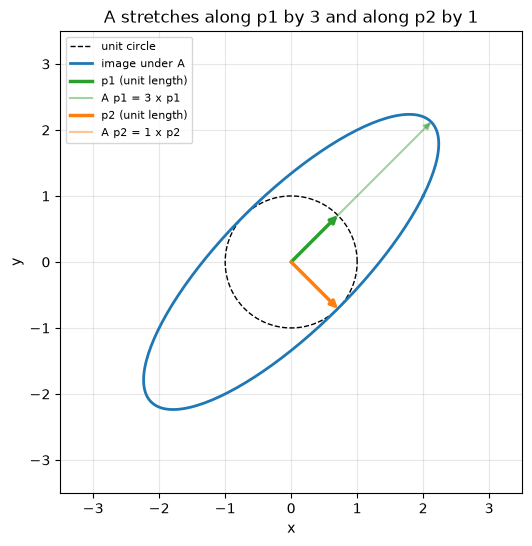

In [15]:
A = np.array([[2., 1.], [1., 2.]])
P = np.array([[1., 1.], [1., -1.]])                  # columns = new basis vectors
x = np.array([3., 1.])
c = np.linalg.solve(P, x)                            # coordinates of x in the new basis
print("x =", x, " new coordinates c =", c, " reconstruct P @ c =", P @ c)
A_new = np.linalg.solve(P, A @ P)                    # P^{-1} A P without forming the inverse
print("P^-1 A P =\n", np.round(A_new, 12) + 0.0)            # (+ 0.0 turns a printed -0. into 0.)
print("invariants  trace: %.1f vs %.1f   det: %.1f vs %.1f" % (np.trace(A), np.trace(A_new), np.linalg.det(A), np.linalg.det(A_new)))

# picture: the unit circle and its image, with the new basis directions
theta = np.linspace(0, 2 * np.pi, 200)
circle = np.vstack([np.cos(theta), np.sin(theta)])
ellipse = A @ circle
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(circle[0], circle[1], "k--", lw=1, label="unit circle")
ax.plot(ellipse[0], ellipse[1], "tab:blue", lw=2, label="image under A")
for i, (col, nm) in enumerate(zip(["tab:green", "tab:orange"], ["p1", "p2"])):
    p = P[:, i] / np.linalg.norm(P[:, i])                       # unit vector along the i-th new basis direction
    ax.annotate("", xy=p, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2.5, shrinkA=0, shrinkB=0))
    ax.annotate("", xy=A @ p, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.5, alpha=0.45, shrinkA=0, shrinkB=0))
    ax.plot([], [], color=col, lw=2.5, label=f"{nm} (unit length)")
    ax.plot([], [], color=col, lw=1.5, alpha=0.45, label=f"A {nm} = {np.linalg.norm(A @ p):.0f} x {nm}")
ax.set_aspect("equal"); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("A stretches along p1 by 3 and along p2 by 1")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

**Notice that** the circle becomes an ellipse whose axes are exactly the new basis directions: along
$\mathbf{p}_1$ the arrow triples (solid green $\to$ faint green), along $\mathbf{p}_2$ it is unchanged
(solid and faint orange coincide), and $P^{-1}AP$ records nothing but those two numbers. Trace and
determinant are the same in both coordinate systems — they belong to the map, not to the matrix.
Finding the basis that makes $A$ diagonal is the eigenvalue problem, and doing it for a covariance
matrix is PCA (Module 03).

## 9. Matrices as graphs and Markov chains

An adjacency matrix $A$ has $A_{ij} = 1$ when there is an edge $i \to j$, and $(A^k)_{ij}$ counts
walks of length $k$. A row-stochastic transition matrix $P$ propagates a distribution:
$\boldsymbol\pi_{t+1} = \boldsymbol\pi_t P$. For a well-behaved chain $\boldsymbol\pi_t$ converges to the
stationary distribution $\boldsymbol\pi$ with $\boldsymbol\pi P = \boldsymbol\pi$, whatever the start.

walks of length 2 (A^2):
 [[3 1 2 1]
 [1 2 1 2]
 [2 1 3 1]
 [1 2 1 2]]
walks of length 3 from node 0 to node 3: 5

rows sum to 1: [1. 1. 1.]
pi after 25 steps : [0.5  0.25 0.25]
row of P^200      : [0.5  0.25 0.25]
eigenvector method: [0.5  0.25 0.25]    check pi P = pi: True
eigenvalues of P  : [1.     0.6732 0.3268]  (second one sets the convergence rate)


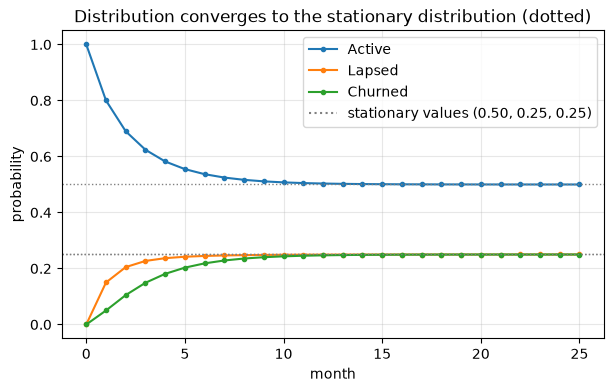

In [16]:
# path counting on a small undirected graph: 0-1, 1-2, 2-3, 3-0, 0-2
Adj = np.array([[0, 1, 1, 1],
                [1, 0, 1, 0],
                [1, 1, 0, 1],
                [1, 0, 1, 0]])
print("walks of length 2 (A^2):\n", Adj @ Adj)
print("walks of length 3 from node 0 to node 3:", np.linalg.matrix_power(Adj, 3)[0, 3])

# a three-state customer chain: Active, Lapsed, Churned-but-returning
Pm = np.array([[0.80, 0.15, 0.05],
               [0.30, 0.50, 0.20],
               [0.10, 0.20, 0.70]])
print("\nrows sum to 1:", Pm.sum(axis=1))
pi = np.array([1., 0., 0.])                           # everyone starts Active
history = [pi]
for step in range(25):
    pi = pi @ Pm
    history.append(pi)
history = np.array(history)

# stationary distribution two ways: a large power, and the eigenvector of P^T for eigenvalue 1
pi_power = np.linalg.matrix_power(Pm, 200)[0]
evals, evecs = np.linalg.eig(Pm.T)
v = np.real(evecs[:, np.argmin(np.abs(evals - 1))]); pi_eig = v / v.sum()
print("pi after 25 steps :", history[-1])
print("row of P^200      :", pi_power)
print("eigenvector method:", pi_eig, "   check pi P = pi:", np.allclose(pi_eig @ Pm, pi_eig))
print("eigenvalues of P  :", np.sort(np.abs(evals))[::-1], " (second one sets the convergence rate)")

for j, lab in enumerate(["Active", "Lapsed", "Churned"]):
    plt.plot(history[:, j], "o-", ms=3, label=lab)
    plt.axhline(pi_eig[j], color="gray", ls=":", lw=1)
plt.plot([], [], color="gray", ls=":", label="stationary values (%.2f, %.2f, %.2f)" % tuple(pi_eig))   # legend entry for the dotted lines
plt.xlabel("month"); plt.ylabel("probability"); plt.title("Distribution converges to the stationary distribution (dotted)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Notice that** after about 15 steps the three curves have flattened onto the dotted stationary
values (two of them coincide at $0.25$), and that the $200$-th power of $P$ has that same vector as
its row — every starting state leads to the same long-run mix. The gap closes geometrically at the
rate of the second-largest eigenvalue modulus, which is the quantity PageRank and MCMC practitioners
care about (Modules 03 and 18); the next figure shows it for all three starting states. The $A^2$
entries are plain path counts: matrix multiplication is doing combinatorics.

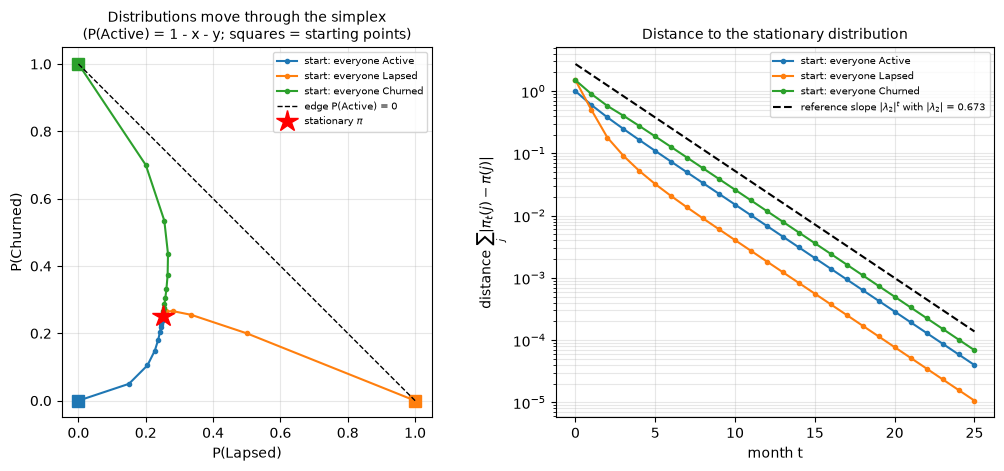

each month the distance shrinks by a factor of about 0.673, i.e. it halves every 1.75 months


In [17]:
# Three starts, one destination: trajectories in the probability simplex, and the distance to pi on a log axis
lam2 = np.sort(np.abs(evals))[::-1][1]                       # second-largest eigenvalue modulus of Pm
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.6), layout="constrained")
gaps_ = []
for j, (name_, col_) in enumerate(zip(["Active", "Lapsed", "Churned"], ["tab:blue", "tab:orange", "tab:green"])):
    traj_ = [np.eye(3)[j]]                                   # everyone starts in state j
    for _ in range(25):
        traj_.append(traj_[-1] @ Pm)
    traj_ = np.array(traj_)
    gaps_.append(np.abs(traj_ - pi_eig).sum(axis=1))         # L1 distance to the stationary distribution
    ax1.plot(traj_[:, 1], traj_[:, 2], "o-", ms=3, color=col_, label=f"start: everyone {name_}")
    ax1.plot(traj_[0, 1], traj_[0, 2], "s", ms=9, color=col_)
    ax2.semilogy(gaps_[-1], "o-", ms=3, color=col_, label=f"start: everyone {name_}")
ax1.plot([0, 1], [1, 0], "k--", lw=1, label="edge P(Active) = 0")   # the hypotenuse of the simplex
ax1.plot(pi_eig[1], pi_eig[2], "r*", ms=16, label=r"stationary $\pi$")
ax1.set_xlabel("P(Lapsed)"); ax1.set_ylabel("P(Churned)")
ax1.set_title("Distributions move through the simplex\n(P(Active) = 1 - x - y; squares = starting points)", fontsize=10)
ax1.set_aspect("equal"); ax1.legend(fontsize=7, loc="upper right"); ax1.grid(alpha=0.3)
months_ = np.arange(26)
ax2.semilogy(months_, 2 * max(g_[20] / lam2 ** 20 for g_ in gaps_) * lam2 ** months_, "k--", lw=1.5,
             label=rf"reference slope $|\lambda_2|^t$ with $|\lambda_2|$ = {lam2:.3f}")
ax2.set_xlabel("month t"); ax2.set_ylabel(r"distance $\sum_j |\pi_t(j) - \pi(j)|$")
ax2.set_title("Distance to the stationary distribution", fontsize=10)
ax2.legend(fontsize=7); ax2.grid(alpha=0.3, which="both")
plt.show()
print("each month the distance shrinks by a factor of about %.3f, i.e. it halves every %.2f months" % (lam2, np.log(2) / -np.log(lam2)))

**Notice that** all three starting points — the corners of the simplex, "everyone Active", "everyone
Lapsed", "everyone Churned" — flow into the same point, the red star: the distribution
$(0.5, 0.25, 0.25)$, which sits at $(0.25, 0.25)$ in these coordinates. On the log axis the three
distances become parallel straight lines with the slope of $|\lambda_2|^t$: every month the distance
to $\boldsymbol\pi$ shrinks by a factor of about $0.673$, so it halves roughly every $1.75$ months.
The starting point only changes the height of the line, never its slope.

## Summary

* $A\mathbf{x}$ is simultaneously a set of dot products (rows), a combination of columns, a linear
  function and a system of equations; the column picture tells you what outputs are reachable.
* `A @ B` composes maps right-to-left, is not commutative (the order changes the picture, not the
  determinant), costs $O(n^3)$, and collapses stacked linear layers into one.
* Rotation, scaling, shear, reflection and projection are $2\times2$ matrices; the determinant is the
  signed area factor, and $\det = 0$ means a dimension was destroyed.
* Orthogonal matrices preserve lengths; Gram matrices $A^\top A$ are symmetric PSD; triangular
  systems solve in $O(n^2)$.
* Rank counts independent columns; duplicated or one-hot-trapped features give a non-trivial null
  space — a flat valley of the loss — and unidentifiable coefficients.
* Use `np.linalg.solve`, never `inv(A) @ b`; the condition number bounds how many digits survive
  whatever the algorithm, but `solve` keeps the residual at rounding level where `inv` does not.
* Least squares = projection onto the column space; the normal equations, QR and `lstsq` agree on
  well-conditioned problems, but QR/SVD avoid squaring $\kappa$ and keep many more digits when it is
  large; the hat matrix is a symmetric idempotent projector.
* $P^{-1}AP$ is the same map in new coordinates — diagonal when $P$ holds the eigenvectors.
* Powers of adjacency matrices count walks; powers of transition matrices converge to the
  stationary distribution, at the rate $|\lambda_2|^t$.

**Next:** open `exercises.ipynb` and work through the twelve exercises; `solutions.ipynb` has
reference implementations and explanations. Then continue with
[Module 03 — Eigenvalues, SVD and PCA](../03-eigenvalues-svd-and-pca/README.md).